In [ ]:
#1.
from sklearn.datasets import load_wine
import pandas as pd

X, y = load_wine(return_X_y=True, as_frame=True)

Perform Recursive Feature Elimination (RFE) using Logistic Regression to select the top 3 features.

Expected Output:
Top 3 selected features using RFE: ['alcohol', 'flavanoids', 'od280/od315_of_diluted_wines']


In [1]:
# Step 1: Import Libraries
import pandas as pd
import warnings

from sklearn.datasets import load_wine
from sklearn.feature_selection import RFE
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

warnings.filterwarnings("ignore", category=FutureWarning)

# Step 2: Load Wine Dataset
X, y = load_wine(return_X_y=True, as_frame=True)

print("Original Dataset Shape:", X.shape)
print("Total Features:", X.shape[1])

# Step 3: Create Logistic Regression Model
model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=10000, random_state=42)
)

# Step 4: Apply Recursive Feature Elimination
rfe = RFE(
    estimator=LogisticRegression(max_iter=10000, random_state=42),
    n_features_to_select=3
)

# Step 5: Scale Features
scaler = StandardScaler()
X_scaled = pd.DataFrame(
    scaler.fit_transform(X),
    columns=X.columns
)

# Step 6: Train RFE
rfe.fit(X_scaled, y)

# Step 7: Get Selected Features
selected_features = X.columns[rfe.support_].tolist()

# Step 8: Display Results
print("\nTop 3 selected features using RFE:")
print(selected_features)

# Step 9: Display Feature Ranking
feature_ranking = pd.DataFrame({
    "Feature": X.columns,
    "Ranking": rfe.ranking_,
    "Selected": rfe.support_
})

print("\nFeature Ranking:")
print(feature_ranking.sort_values("Ranking"))

# Step 10: Create Final Dataset
X_selected = X[selected_features]

print("\nSelected Dataset Shape:", X_selected.shape)
print("\nFirst 5 Rows:")
print(X_selected.head())

Original Dataset Shape: (178, 13)
Total Features: 13

Top 3 selected features using RFE:
['flavanoids', 'color_intensity', 'proline']

Feature Ranking:
                         Feature  Ranking  Selected
6                     flavanoids        1      True
9                color_intensity        1      True
12                       proline        1      True
0                        alcohol        2     False
10                           hue        3     False
11  od280/od315_of_diluted_wines        4     False
2                            ash        5     False
3              alcalinity_of_ash        6     False
8                proanthocyanins        7     False
1                     malic_acid        8     False
5                  total_phenols        9     False
7           nonflavanoid_phenols       10     False
4                      magnesium       11     False

Selected Dataset Shape: (178, 3)

First 5 Rows:
   flavanoids  color_intensity  proline
0        3.06             5.64 

In [ ]:
#2.
from sklearn.datasets import load_digits
import pandas as pd

X, y = load_digits(return_X_y=True, as_frame=True)

Perform PCA for dimensionality reduction and reduce the dataset to 3 components.

expected output:
    
Transformed dataset (3 components):
 [[ -1.2594664   21.27488439  -9.46305689]
 [  7.9576113  -20.76870018   4.43950399]
 [  6.99192304  -9.9559863    2.95856164]
 ...
 [ 10.80128394  -6.96025023   5.59956528]
 [ -4.87210013  12.42395227 -10.17088928]
 [ -0.34438951   6.36555114  10.77371663]]


In [2]:
# Step 1: Import Libraries
import pandas as pd
import numpy as np
from sklearn.datasets import load_digits
from sklearn.decomposition import PCA

# Step 2: Load Dataset
X, y = load_digits(return_X_y=True, as_frame=True)

print("Original Dataset Shape:", X.shape)

# Step 3: Apply PCA
pca = PCA(n_components=3)

# Step 4: Fit and Transform
X_pca = pca.fit_transform(X)

# Step 5: Display Results
print("\nTransformed dataset (3 components):")
print(X_pca)

# Step 6: Display New Shape
print("\nTransformed Dataset Shape:", X_pca.shape)

# Step 7: Explained Variance
print("\nExplained Variance Ratio:")
print(pca.explained_variance_ratio_)

# Step 8: Create PCA DataFrame
pca_df = pd.DataFrame(
    X_pca,
    columns=["PC1", "PC2", "PC3"]
)

print("\nFirst 5 Rows:")
print(pca_df.head())

Original Dataset Shape: (1797, 64)

Transformed dataset (3 components):
[[ -1.25946645 -21.27488348   9.46305462]
 [  7.9576113   20.76869896  -4.43950604]
 [  6.99192297   9.95598641  -2.95855808]
 ...
 [ 10.8012837    6.96025223  -5.59955453]
 [ -4.87210009 -12.42395362  10.17086635]
 [ -0.34438963  -6.36554919 -10.77370849]]

Transformed Dataset Shape: (1797, 3)

Explained Variance Ratio:
[0.14890594 0.13618771 0.11794594]

First 5 Rows:
         PC1        PC2       PC3
0  -1.259466 -21.274883  9.463055
1   7.957611  20.768699 -4.439506
2   6.991923   9.955986 -2.958558
3 -15.906105  -3.332464 -9.824372
4  23.306867  -4.269061  5.675129


In [ ]:
#3.
from sklearn.datasets import load_iris
import pandas as pd

X, y = load_iris(return_X_y=True, as_frame=True)

Perform t-SNE dimensionality reduction to reduce the dataset to 2 dimensions.


Original Dataset Shape: (150, 4)

Transformed Dataset (2 Dimensions):
[[-24.310734    -2.1122737 ]
 [-20.536928    -1.3836074 ]
 [-21.545553    -2.4164944 ]
 [-20.773043    -2.4609888 ]
 [-24.798649    -2.6877975 ]
 [-26.65752     -2.3595505 ]
 [-22.569906    -3.186175  ]
 [-23.319975    -2.1404238 ]
 [-19.732718    -2.2219427 ]
 [-21.245077    -1.483448  ]
 [-25.810587    -1.8049806 ]
 [-22.936747    -2.709618  ]
 [-20.392296    -1.7871201 ]
 [-20.054565    -2.8429148 ]
 [-27.24293     -1.8478546 ]
 [-27.80786     -2.3885565 ]
 [-26.66813     -2.2631319 ]
 [-24.288963    -2.154971  ]
 [-26.556307    -1.604251  ]
 [-25.976902    -2.7811291 ]
 [-24.208616    -1.0458821 ]
 [-25.437477    -2.6920624 ]
 [-24.107643    -3.715449  ]
 [-22.946922    -1.2514149 ]
 [-22.91918     -2.7647376 ]
 [-20.757689    -1.0968368 ]
 [-23.37271     -2.1589797 ]
 [-24.525938    -1.7919464 ]
 [-23.762068    -1.4953113 ]
 [-21.592394    -2.383908  ]
 [-21.07531     -1.951836  ]
 [-24.15608     -1.0181377 ]
 [

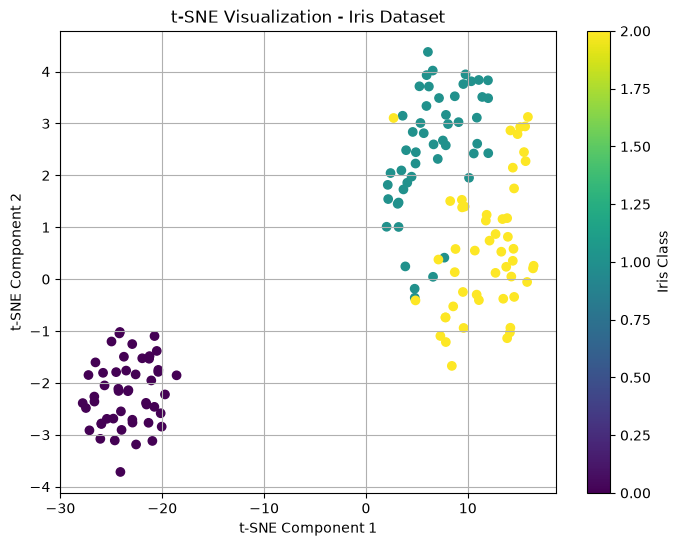

In [3]:
# Step 1: Import Libraries
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler

# Step 2: Load Iris Dataset
X, y = load_iris(return_X_y=True, as_frame=True)

print("Original Dataset Shape:", X.shape)

# Step 3: Standardize Features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Step 4: Apply t-SNE
tsne = TSNE(
    n_components=2,
    perplexity=30,
    random_state=42,
    init='pca',
    learning_rate='auto'
)

# Step 5: Fit and Transform
X_tsne = tsne.fit_transform(X_scaled)

# Step 6: Display Results
print("\nTransformed Dataset (2 Dimensions):")
print(X_tsne)

# Step 7: Display Shape
print("\nTransformed Dataset Shape:", X_tsne.shape)

# Step 8: Create DataFrame
tsne_df = pd.DataFrame(
    X_tsne,
    columns=['TSNE1', 'TSNE2']
)

tsne_df['Target'] = y.values

print("\nFirst 5 Rows:")
print(tsne_df.head())

# Step 9: Visualize t-SNE
plt.figure(figsize=(8, 6))

scatter = plt.scatter(
    tsne_df['TSNE1'],
    tsne_df['TSNE2'],
    c=tsne_df['Target'],
    cmap='viridis'
)

plt.title('t-SNE Visualization - Iris Dataset')
plt.xlabel('t-SNE Component 1')
plt.ylabel('t-SNE Component 2')
plt.colorbar(scatter, label='Iris Class')
plt.grid(True)
plt.show()

In [ ]:
#4.
import pandas as pd

# Create a mock dataset of users and movie ratings
data = {'User': ['U1', 'U2', 'U3', 'U4', 'U5'],
        'Movie A': [5, 4, 0, 1, 2],
        'Movie B': [4, 0, 5, 2, 3],
        'Movie C': [1, 2, 4, 5, 0],
        'Movie D': [0, 1, 2, 3, 4]}

df = pd.DataFrame(data)

Use Cosine Similarity to recommend movies to User U1 based on their similarity to other users.

In [4]:
# Step 1: Import Libraries
import pandas as pd
from sklearn.metrics.pairwise import cosine_similarity

# Step 2: Create Dataset
data = {
    'User': ['U1', 'U2', 'U3', 'U4', 'U5'],
    'Movie A': [5, 4, 0, 1, 2],
    'Movie B': [4, 0, 5, 2, 3],
    'Movie C': [1, 2, 4, 5, 0],
    'Movie D': [0, 1, 2, 3, 4]
}

df = pd.DataFrame(data)
ratings = df.set_index('User')

print("User Movie Ratings:")
print(ratings)

# Step 3: Calculate Cosine Similarity
similarity = cosine_similarity(ratings)

similarity_df = pd.DataFrame(
    similarity,
    index=ratings.index,
    columns=ratings.index
)

print("\nUser Similarity Matrix:")
print(similarity_df.round(3))

# Step 4: Find Similar Users to U1
user = 'U1'

similar_users = similarity_df[user].drop(user)
similar_users = similar_users.sort_values(ascending=False)

print("\nSimilar Users to U1:")
print(similar_users)

# Step 5: Find Unwatched Movies
# 0 means not rated
unwatched = ratings.loc[user][ratings.loc[user] == 0].index

# Step 6: Predict Ratings
recommendations = {}

for movie in unwatched:
    movie_ratings = ratings.loc[similar_users.index, movie]
    rated_mask = movie_ratings > 0

    weights = similar_users[rated_mask]
    scores = movie_ratings[rated_mask]

    if weights.sum() > 0:
        predicted_rating = (
            (scores * weights).sum() / weights.sum()
        )
        recommendations[movie] = predicted_rating

# Step 7: Recommend Movies
recommendations = pd.Series(
    recommendations,
    dtype=float
).sort_values(ascending=False)

print("\nRecommended Movies for U1:")
print(recommendations.round(2))

User Movie Ratings:
      Movie A  Movie B  Movie C  Movie D
User                                    
U1          5        4        1        0
U2          4        0        2        1
U3          0        5        4        2
U4          1        2        5        3
U5          2        3        0        4

User Similarity Matrix:
User     U1     U2     U3     U4     U5
User                                   
U1    1.000  0.741  0.552  0.445  0.630
U2    0.741  1.000  0.325  0.594  0.486
U3    0.552  0.325  1.000  0.859  0.637
U4    0.445  0.594  0.859  1.000  0.595
U5    0.630  0.486  0.637  0.595  1.000

Similar Users to U1:
User
U2    0.740779
U5    0.630375
U3    0.552052
U4    0.444750
Name: U1, dtype: float64

Recommended Movies for U1:
Movie D    2.41
dtype: float64


In [ ]:
#5.
from sklearn.datasets import load_digits
digits = load_digits()
X = digits.data


Expected output:
Reduced shape: (1797, 2)


In [5]:
# Step 1: Import Libraries
from sklearn.datasets import load_digits
from sklearn.decomposition import PCA

# Step 2: Load Dataset
digits = load_digits()
X = digits.data

# Step 3: Apply PCA
pca = PCA(n_components=2)

# Step 4: Fit and Transform
X_reduced = pca.fit_transform(X)

# Step 5: Display Output
print("Original shape:", X.shape)
print("Reduced shape:", X_reduced.shape)

Original shape: (1797, 64)
Reduced shape: (1797, 2)
